# Exploratory Data Analysis (EDA)

This notebook performs data quality checks and exploratory analysis on the Country Aid dataset before preprocessing and clustering. The objective is to understand the structure, distributions, extreme observations, and potential modelling considerations in the data.

## 1. Setup

Set up the required Python libraries and load the COuntry Aid dataset for analysis

### 1.1 Import Libraries

Import the required Python libraries for data manipulation and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 1.2 Load the Dataset

Load the Country Aid dataset into a Pandas DataFrame for inspection and analysis.

In [2]:
df = pd.read_csv("/Users/avdhootkulkarni/Desktop/country-aid-clustering/data/raw/Country-data.csv")
df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


## 2. Data Audit

The dataset is examined for its structure, data types, completeness, duplicate records, and basic data-quality issues before detailed exploratory analysis.

### 2.1 Dataset Structure and Data Types

In [3]:
df.shape

(167, 10)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB


**Observation:**
- The dataset contains 167 rows and 10 columns.
- `country` is the categorical identifier, while the remaining 9 features are numerical.
- The numerical data types are appropriate for the respective variables.
- All columns contain 167 non-null observations.

### 2.2 Missing Values and Duplicate Records

Check the dataset for missing values and duplicate records to identify whether any data cleaning is required.

In [5]:
df.isnull().sum()

country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

**Observation:**
- No missing values are present in any of the 10 columns.
- No completely duplicated rows are present in the dataset.
- Therefore, no missing-value treatment or duplicate removal is required at this stage.

### 2.3 Descriptive Statistics

Generate summary statistics for the numerical features to understand their central tendency, spread, range, and quartile distribution.

In [7]:
df.describe()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


**Observation:**
- The numerical features operate on very different scales. For example, total fertility is mostly within single-digit values, while income and GDP per capita reach values above 100,000.
- Several variables show a large gap between the third quartile and the maximum value, suggesting the presence of extreme observations.
- Inflation includes a negative minimum value, which may represent deflation rather than a data-quality issue.
- Life expectancy shows a much lower minimum compared with its lower quartile, while child mortality, income, inflation, imports, exports, and GDP per capita show unusually high maximum values.
- These extreme values require further investigation through outlier and distribution analysis before modelling.

In [8]:
df.describe(include=str)

,country
count,167
unique,167
top,Afghanistan
freq,1


**Observation:**
- The `country` column contains 167 records and 167 unique values.
- This confirms that each country appears only once in the dataset.
- Therefore, there are no duplicate country-level observations.

### 2.4 Extreme and Suspicious Values

Inspect the minimum and maximum values of key numerical features and identify the countries associated with extreme observations. The objective is to distinguish genuine extreme conditions from possible data-quality issues.

In [9]:
df[df['child_mort']== df['child_mort'].max()][['country','child_mort']]

,country,child_mort
66,Haiti,208.0


In [10]:
df[df['life_expec'] ==df['life_expec'].min()][['country','life_expec']]

,country,life_expec
66,Haiti,32.1


In [11]:
df[df['income'] ==df['income'].max()][['country','income']]

,country,income
123,Qatar,125000


In [12]:
df[df['gdpp'] ==df['gdpp'].max()][['country','gdpp']]

,country,gdpp
91,Luxembourg,105000


In [13]:
df[df['inflation'] ==df['inflation'].max()][['country','inflation']]

,country,inflation
113,Nigeria,104.0


In [14]:
df[df['inflation'] ==df['inflation'].min()][['country','inflation']]

,country,inflation
131,Seychelles,-4.21


In [15]:
df[df['imports'] ==df['imports'].max()][['country','imports']]

,country,imports
133,Singapore,174.0


In [16]:
df[df['exports'] ==df['exports'].max()][['country','exports']]

,country,exports
133,Singapore,200.0


**Observation:**
- Haiti records the highest child mortality (`208`) and the lowest life expectancy (`32.1`), indicating severe human-development vulnerability.
- Qatar has the highest income (`125,000`), while Luxembourg has the highest GDP per capita (`105,000`).
- Nigeria has the highest inflation (`104%`), whereas Seychelles has the lowest inflation (`-4.21%`). The negative inflation value may represent deflation and is not automatically considered invalid.
- Singapore has the highest imports (`174% of GDP`) and exports (`200% of GDP`). Trade values above 100% of GDP are possible and do not necessarily indicate data errors.
- These extreme observations appear plausible and are retained for further analysis rather than being removed automatically.

## 3. Univariate Analysis

Analyze each numerical feature individually to understand its distribution, skewness, spread, and potential outliers.

In [17]:
num_col= df.select_dtypes(include='number').columns
num_col

Index(['child_mort', 'exports', 'health', 'imports', 'income', 'inflation',
       'life_expec', 'total_fer', 'gdpp'],
      dtype='str')

### 3.1 Box Plot Analysis

Box plots are used to visually inspect the spread of each numerical feature and identify potential outliers using the interquartile range (IQR) concept.

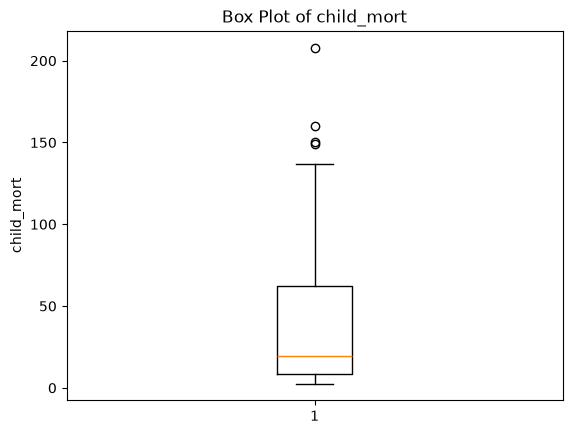

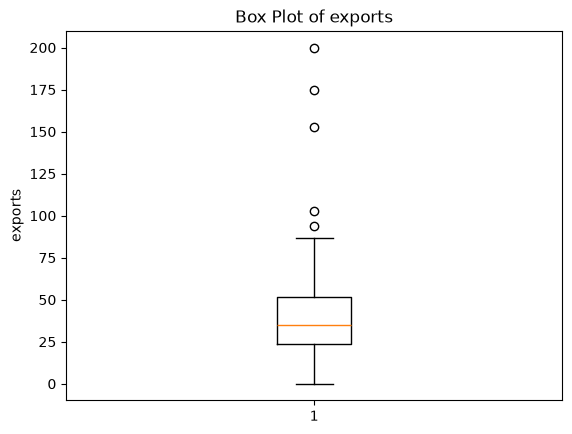

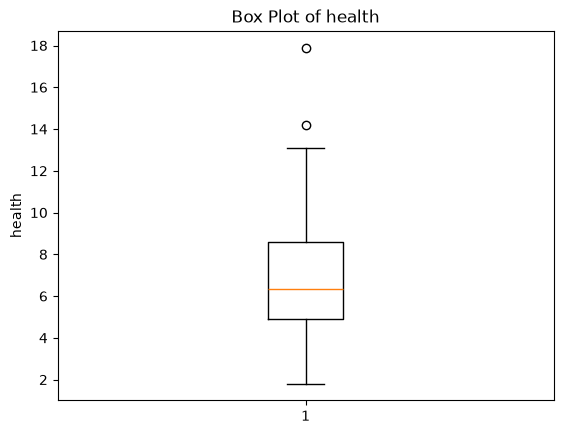

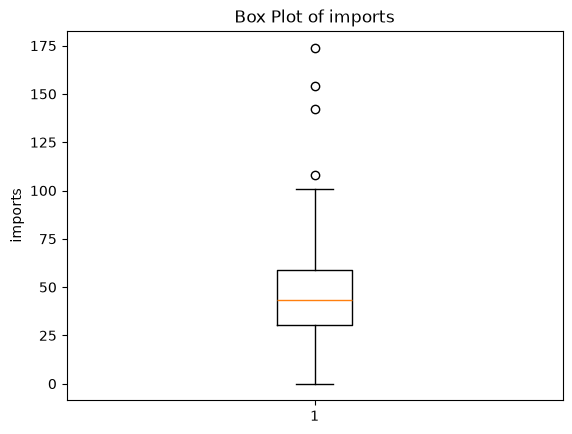

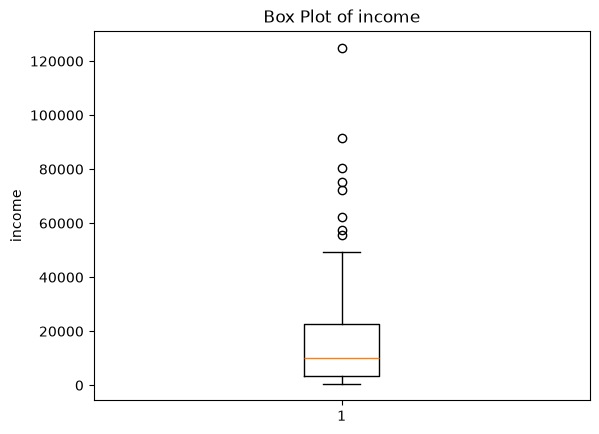

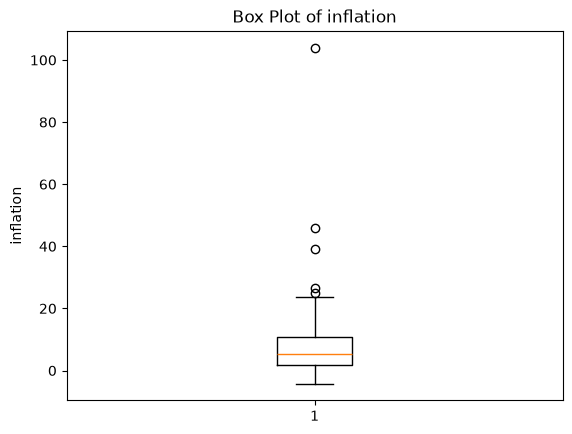

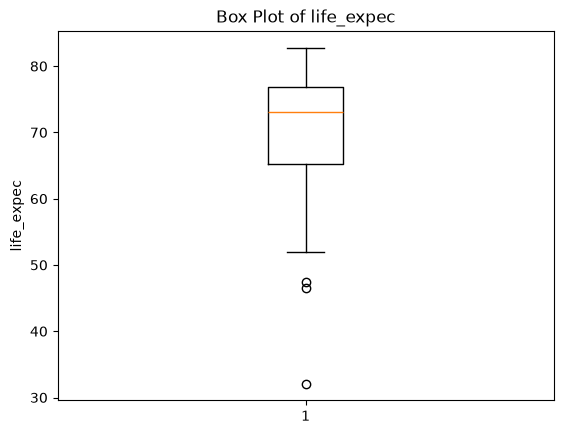

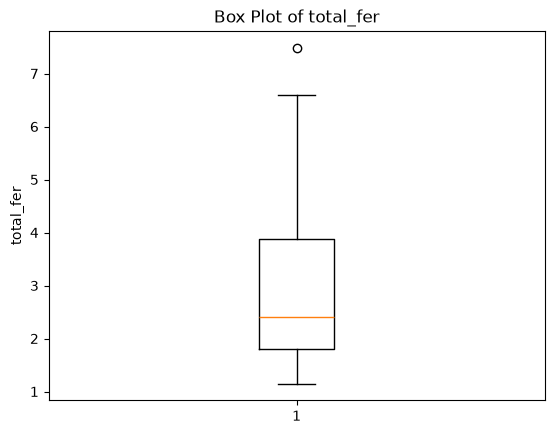

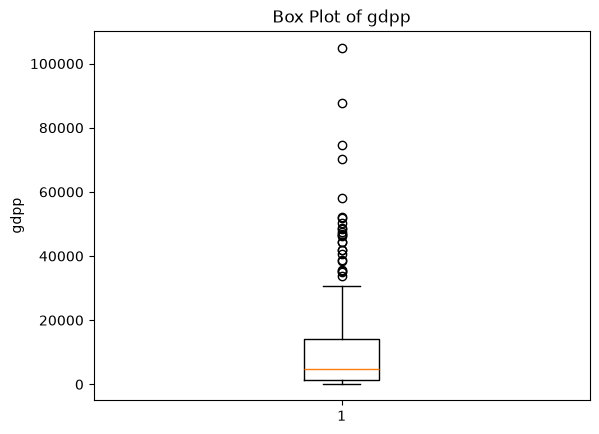

In [18]:
for col in num_col:
    plt.figure()
    plt.boxplot(df[col])
    plt.ylabel(col)
    plt.title(f"Box Plot of {col}")
    plt.show()

**Observation:**
- Potential outliers are visible in several numerical features.
- `child_mort`, `exports`, `health`, `imports`, `income`, `inflation`, `total_fer`, and `gdpp` show outliers predominantly on the higher side.
- `life_expec` shows potential outliers on the lower side.
- The presence of an outlier does not necessarily indicate an incorrect value. In this humanitarian aid context, extreme observations may represent countries experiencing genuinely unusual economic or development conditions.
- Therefore, outliers are not removed solely based on the box plots and require contextual evaluation before preprocessing.

#### 3.1.1 IQR-Based Outlier Detection: Child Mortality

To understand how box plots identify potential outliers, the IQR method is demonstrated explicitly for child mortality.

A value is considered a potential outlier when it falls below:

`Q1 - 1.5 × IQR`

or above:

`Q3 + 1.5 × IQR`.

In [19]:
Q1 = df['child_mort'].quantile(0.25)
Q3 = df['child_mort'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(Q1,Q3,IQR, lower_bound,upper_bound)

8.25 62.1 53.85 -72.525 142.875


In [20]:
outliers = df[(df['child_mort']> upper_bound) | (df['child_mort'] < lower_bound)][['country','child_mort']]
outliers

,country,child_mort
31,Central African Republic,149.0
32,Chad,150.0
66,Haiti,208.0
132,Sierra Leone,160.0


**Observation:**
- The IQR method identifies four potential high-end outliers in child mortality: Central African Republic, Chad, Sierra Leone, and Haiti.
- No lower-end outliers are detected.
- These countries are retained because exceptionally high child mortality is meaningful for the aid-allocation objective and does not appear to represent erroneous data.

### 3.2 Distribution Analysis Using Histograms

Histograms are used to examine the shape, concentration, spread, and skewness of each numerical feature.

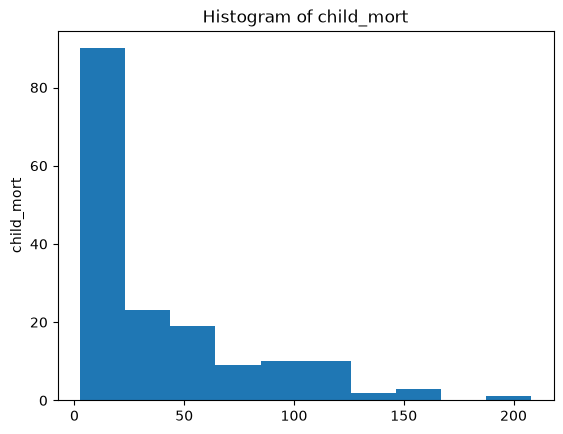

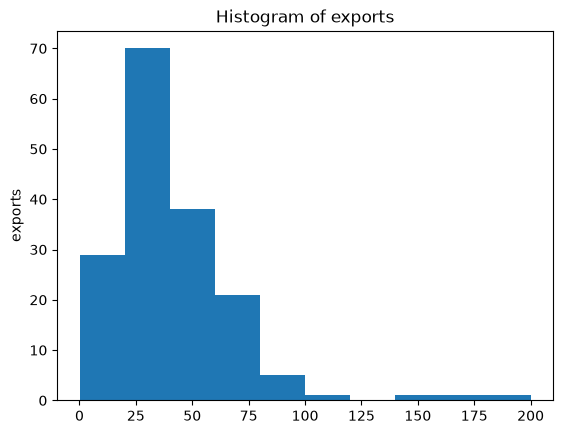

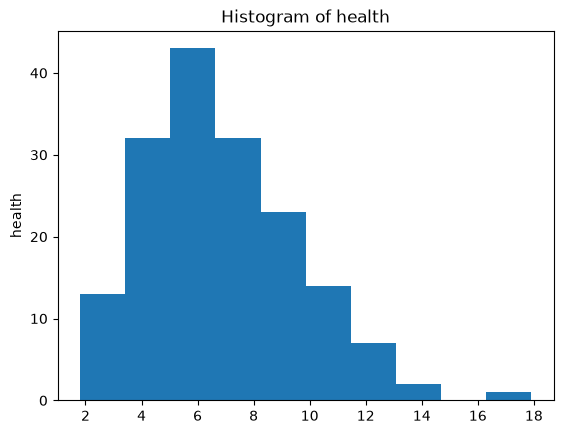

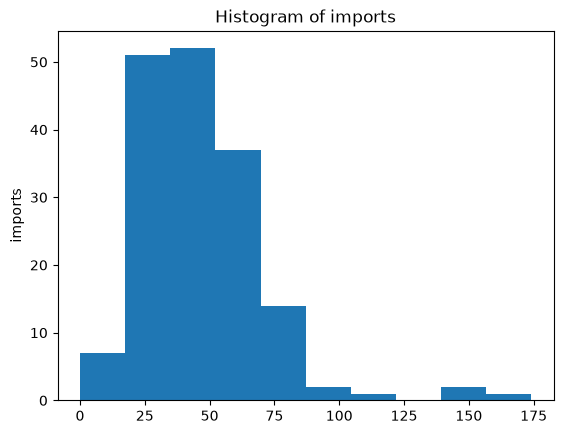

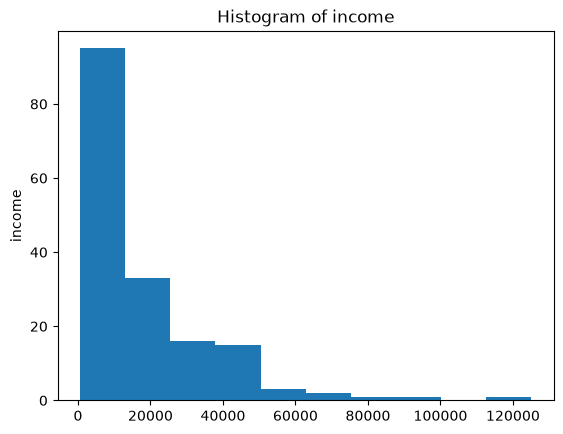

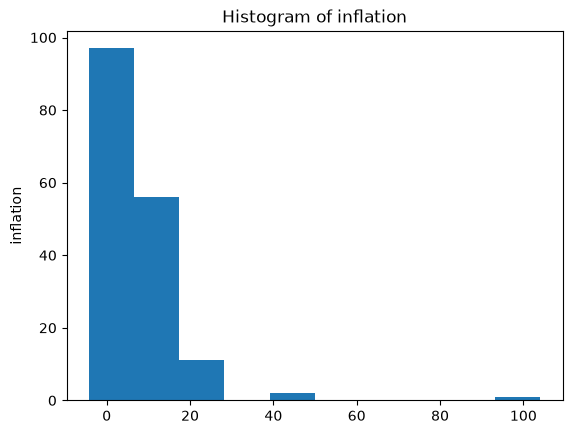

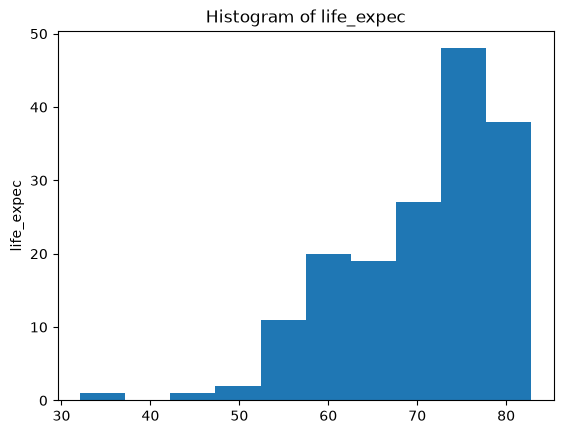

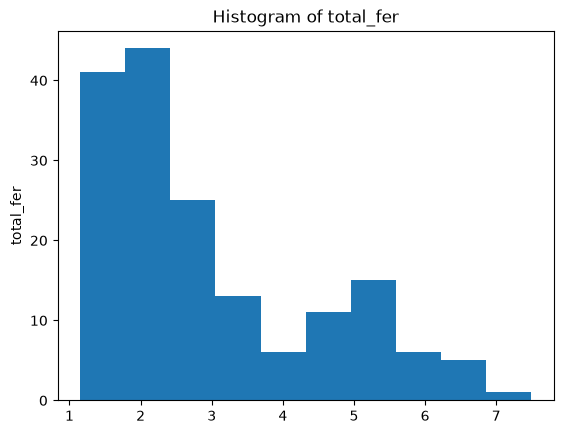

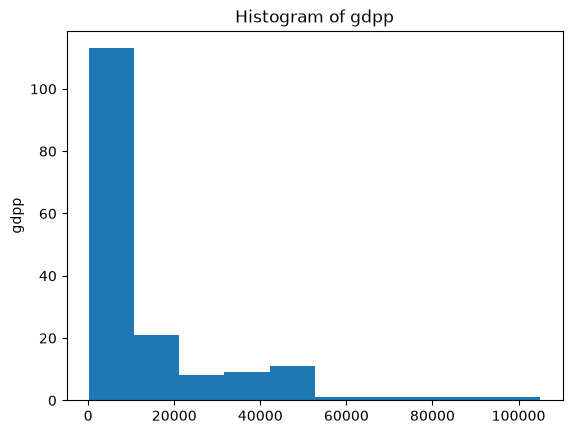

In [21]:
for col in num_col:
    plt.figure()
    plt.hist(df[col])
    plt.ylabel(col)
    plt.title(f"Histogram of {col}")
    plt.show()

**Observation:**
- `child_mort`, `income`, `inflation`, and `gdpp` are strongly right-skewed.
- `exports`, `imports`, and `total_fer` also show right-skewed distributions, though less strongly.
- `health` appears relatively closer to symmetric, with only mild right skew.
- `life_expec` is left-skewed, with most countries concentrated at higher life expectancy values and a smaller number extending toward much lower values.
- Strong skewness and extreme values may influence distance-based clustering algorithms such as K-Means, so transformations and scaling should be considered during preprocessing.

## 4. Data Audit Summary

- The dataset contains 167 unique countries and 9 numerical development indicators.
- No missing values or duplicate records were identified.
- Data types are appropriate for analysis.
- Several genuine extreme observations and statistical outliers are present.
- These observations are retained because they may represent important socioeconomic or human-development conditions rather than data errors.
- Multiple variables show substantial skewness, which will be considered during preprocessing and clustering.

In [41]:
df[num_col].skew().round(2)

child_mort    1.45
exports       2.45
health        0.71
imports       1.91
income        2.23
inflation     5.15
life_expec   -0.97
total_fer     0.97
gdpp          2.22
dtype: float64

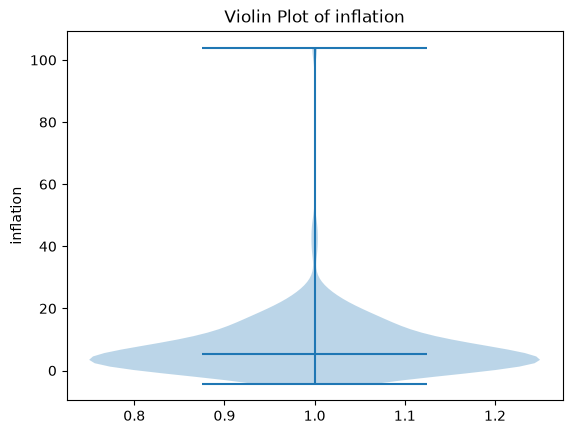

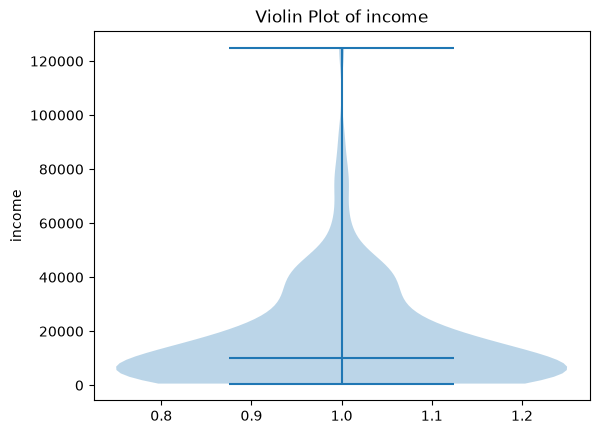

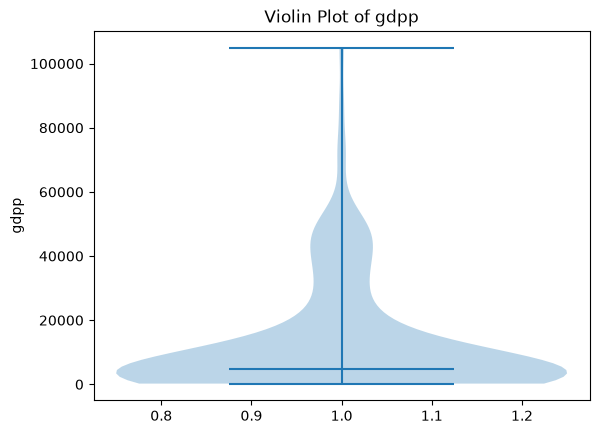

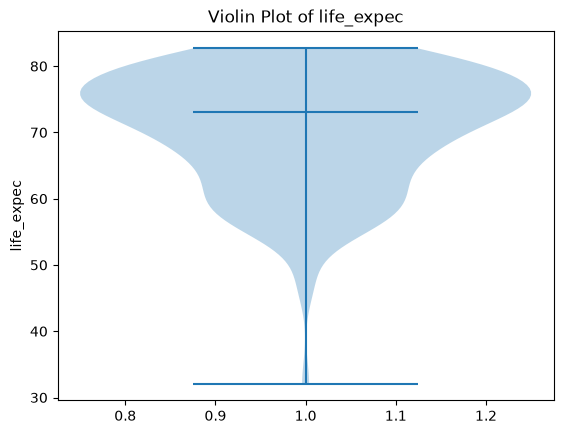

In [23]:
violin_cols = ['inflation', 'income', 'gdpp', 'life_expec']

for col in violin_cols:
    plt.figure()
    plt.violinplot(df[col], showmedians=True)
    plt.ylabel(col)
    plt.title(f"Violin Plot of {col}")
    plt.show()

**Observation:**
- Inflation shows a highly right-skewed distribution, with most countries concentrated at relatively low inflation levels and a small number of countries exhibiting extremely high inflation.
- Income and GDP per capita are strongly right-skewed. Most countries are concentrated at lower values, while relatively few countries extend toward very high economic levels.
- Life expectancy shows a different pattern, with most countries concentrated between approximately 70 and 80 years and a long tail toward lower values, consistent with its negative skewness.
- The violin plots reinforce the patterns observed through histograms and numerical skewness while also showing where observations are most densely concentrated.

## 4. Multivariate Analysis

Multivariate analysis is performed to examine relationships between numerical features, identify strongly associated variables, and detect potential redundancy relevant to clustering.

### 4.1 Correlation Analysis

Analyze the relationships between numerical features to identify strong positive or negative associations and potential feature redundancy before clustering.

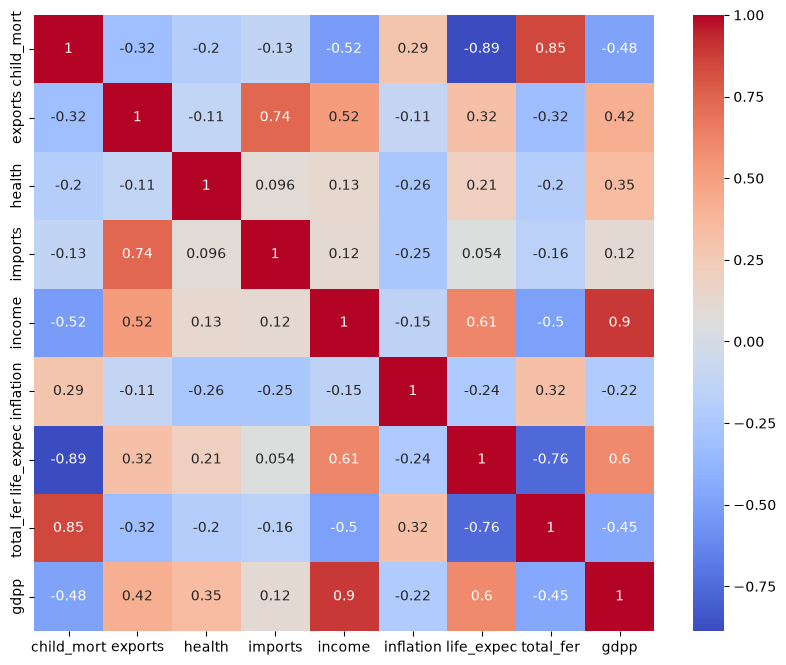

In [32]:
corr_matrix = df[num_col].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot =True,cmap='coolwarm')
plt.show()



**Observation:**
- `income` and `gdpp` show the strongest positive correlation (`0.90`), indicating that countries with higher income levels generally also have higher GDP per capita.
- `child_mort` and `total_fer` are also strongly positively correlated (`0.85`).
- `exports` and `imports` show a strong positive correlation (`0.74`), suggesting that countries with higher export activity also tend to have higher import activity.
- `child_mort` and `life_expec` show the strongest negative correlation (`-0.89`).
- `total_fer` and `life_expec` also show a strong negative correlation (`-0.76`).
- Some highly correlated features may contain overlapping information. This will be considered during preprocessing so that one underlying development dimension is not unintentionally over-represented in clustering.
- Correlation indicates association and should not be interpreted as causation.

### 4.2 Important Feature Relationships

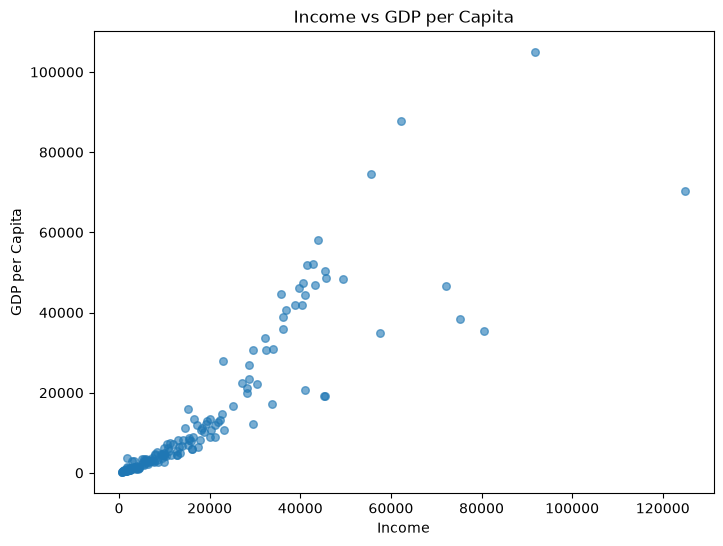

In [37]:
plt.figure(figsize=(8, 6))

plt.scatter(df['income'], df['gdpp'], alpha=0.6,s=30)

plt.xlabel('Income')
plt.ylabel('GDP per Capita')
plt.title('Income vs GDP per Capita')

plt.show()

**Observation:**
- Income and GDP per capita show a strong positive relationship, consistent with their high correlation coefficient (`0.90`).
- At lower and middle income levels, the relationship appears relatively concentrated, with GDP per capita generally increasing as income increases.
- At higher income levels, the observations become more dispersed, indicating that countries with similar high incomes can have noticeably different GDP per capita values.
- A few countries lie far from the main concentration of observations and may represent influential or unusual economic profiles.
- The strong relationship between `income` and `gdpp` suggests that these variables may contain overlapping economic information, which should be considered during feature selection or dimensionality reduction before clustering.

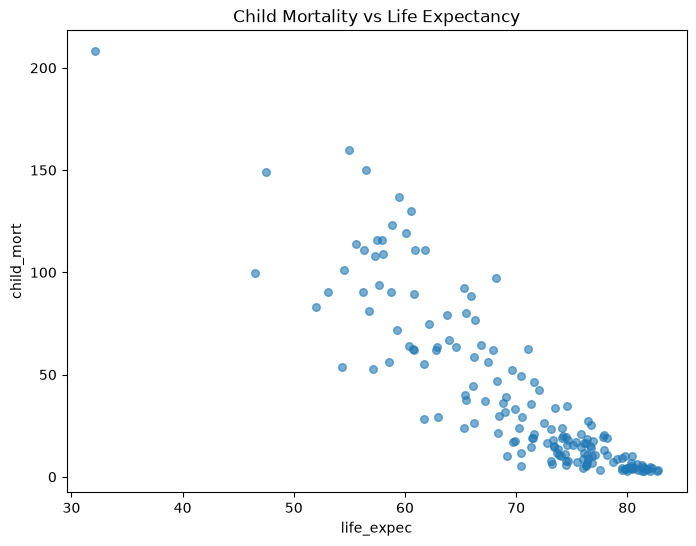

In [39]:
plt.figure(figsize=(8, 6))

plt.scatter(df['life_expec'], df['child_mort'], alpha=0.6,s=30)

plt.xlabel('life_expec')
plt.ylabel('child_mort')
plt.title('Child Mortality vs Life Expectancy')

plt.show()

**Observation:**
- Child mortality and life expectancy show a strong negative relationship, consistent with their correlation coefficient of approximately `-0.89`.
- Countries with higher life expectancy generally have lower child mortality.
- The relationship is not perfectly linear; child mortality declines sharply as life expectancy increases and becomes more concentrated at lower values among countries with high life expectancy.
- A large number of countries are concentrated around 70–80 years of life expectancy with relatively low child mortality.
- A few countries exhibit extremely low life expectancy and very high child mortality, representing severe human-development vulnerability.

Text(0.5, 1.0, 'Total Fertility vs Child Mortality')

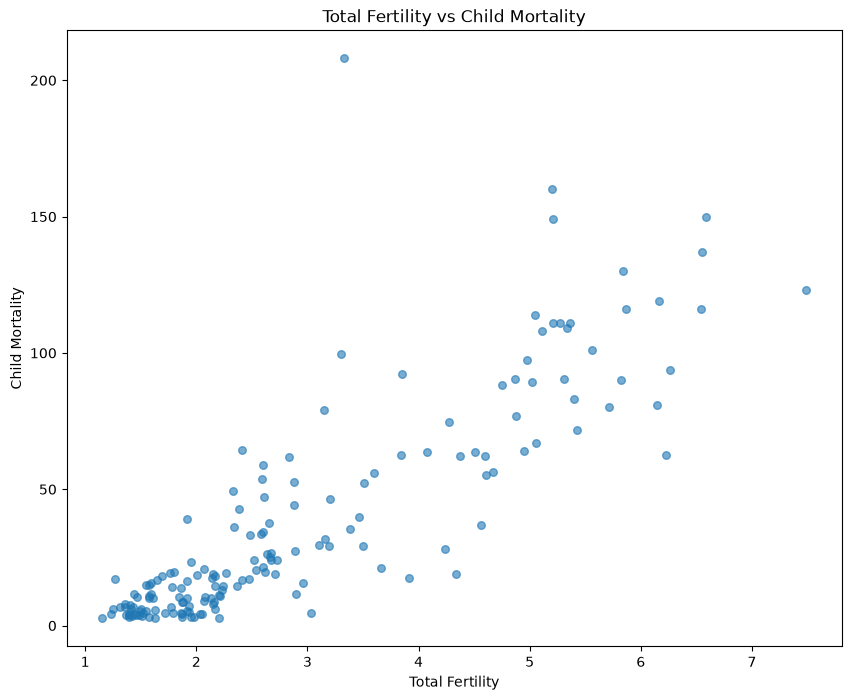

In [40]:
plt.figure(figsize=(10,8))
plt.scatter(df['total_fer'],df['child_mort'],alpha=0.6, s= 30)
plt.xlabel("Total Fertility")
plt.ylabel("Child Mortality")
plt.title("Total Fertility vs Child Mortality")

**Observation:**
- Total fertility and child mortality show a strong positive relationship, consistent with their correlation coefficient of approximately `0.85`.
- Countries with higher fertility rates generally tend to have higher child mortality.
- The relationship is not perfectly linear, and the variation in child mortality becomes larger at higher fertility levels.
- Most countries with low fertility rates also exhibit relatively low child mortality.
- A few extreme observations are present, but these may represent genuine development vulnerability rather than data errors.
- This relationship indicates substantial overlap between fertility and child mortality as development indicators, which should be considered during preprocessing and clustering.

## 5. EDA Summary and Modelling Considerations

- The dataset contains complete records for 167 unique countries with no missing values or duplicate observations.
- Several variables contain extreme observations, but these values appear contextually plausible and may represent countries experiencing genuine socioeconomic or human-development vulnerability. They are therefore not removed solely because they are statistical outliers.
- Most numerical variables are positively skewed. Inflation shows the strongest right skew, while life expectancy is negatively skewed.
- Income and GDP per capita are strongly positively correlated (`0.90`), suggesting substantial overlap in the economic information represented by these features.
- Child mortality is strongly negatively associated with life expectancy (`-0.89`) and strongly positively associated with total fertility (`0.85`).
- Total fertility and life expectancy are also strongly negatively correlated (`-0.76`), indicating that several human-development indicators may capture overlapping underlying conditions.
- Imports and exports show a strong positive correlation (`0.74`), reflecting related external economic activity.
- Scatter plots confirm that several relationships are strong but not necessarily perfectly linear and that extreme country profiles remain visible.
- Strong skewness, extreme observations, different feature scales, and highly correlated variables must therefore be considered carefully during preprocessing before distance-based clustering.
- Feature transformation, outlier treatment, feature redundancy, and scaling will be evaluated separately rather than applying automatic preprocessing rules.